# Implied Volatility Smile and SVI Calibration

Implied volatility extracted by inverting the Black-Scholes formula, and a constrained non-linear calibration of Gatheral's SVI model on a single maturity (the smile).

---
## 1. Black-Scholes model and Brent inversion

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize, brentq

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

def bs_call(S, K, T, r, sigma):
    if T <= 0:
        return max(S - K, 0.0)
    if sigma <= 0:
        return max(S - K * np.exp(-r * T), 0.0)   # limit as sigma -> 0: discounted intrinsic value
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def get_iv(market_price, S, K, T, r):
    # Outside the no-arbitrage bounds max(S - K e^{-rT}, 0) < C < S the implied volatility does not exist
    if not (max(S - K * np.exp(-r * T), 0.0) < market_price < S):
        return np.nan
    objective = lambda sigma: bs_call(S, K, T, r, sigma) - market_price
    try:
        return brentq(objective, 1e-4, 5.0)
    except ValueError:   # no sign change in [1e-4, 5]
        return np.nan

## 2. Raw SVI calibration

Implied volatilities computed: 25 of 25
SVI parameters: a=0.0071, b=0.0630, rho=-0.2243, m=0.1033, sigma=0.1351
RMSE of the fit vs market IV: 0.0097 | vs true IV: 0.0073
min g(k) for k in [-1.5, 1.5]: 0.2619 -> no butterfly arbitrage


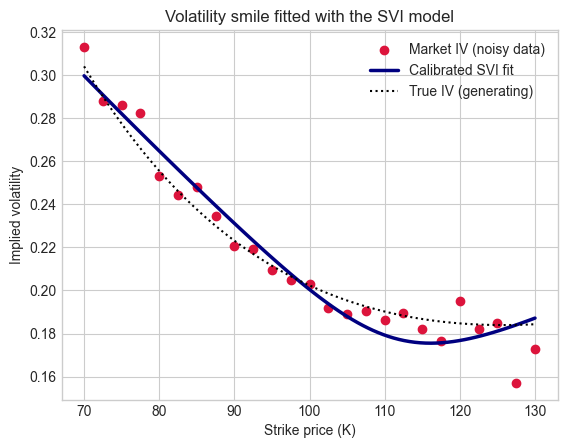

In [2]:
np.random.seed(42)
S0, r, T = 100.0, 0.03, 0.5
strikes = np.linspace(70, 130, 25)
k_vals = np.log(strikes / (S0 * np.exp(r * T)))

# Theoretical implied volatility plus market noise on prices
true_iv = 0.20 - 0.15 * k_vals + 0.35 * (k_vals**2)
prices = np.array([bs_call(S0, K, T, r, sig) for K, sig in zip(strikes, true_iv)])
prices += np.random.normal(0, 0.1, size=len(prices))
ivs = np.array([get_iv(p, S0, K, T, r) for p, K in zip(prices, strikes)])

# SVI model: w(k) = a + b * (rho*(k-m) + sqrt((k-m)^2 + sigma^2))
def svi(k, a, b, rho, m, sigma):
    return a + b * (rho * (k - m) + np.sqrt((k - m)**2 + sigma**2))

def svi_obj(params, k_arr, w_arr):
    return np.sum((svi(k_arr, *params) - w_arr)**2)

# Drop prices that the noise pushed outside the no-arbitrage bounds (undefined implied volatility)
ok = ~np.isnan(ivs)
print(f"Implied volatilities computed: {ok.sum()} of {len(ivs)}")
strikes, k_vals, ivs, true_iv = strikes[ok], k_vals[ok], ivs[ok], true_iv[ok]

w_market = (ivs**2) * T
bounds = [(None, None), (0, None), (-0.99, 0.99), (None, None), (1e-4, None)]
res = minimize(svi_obj, [0.02, 0.1, -0.2, 0.0, 0.1], args=(k_vals, w_market), method='SLSQP', bounds=bounds,
               constraints=[
                   # minimum total variance a + b*sigma*sqrt(1-rho^2) >= 0
                   {'type': 'ineq', 'fun': lambda p: p[0] + p[1] * p[4] * np.sqrt(1 - p[2]**2)},
                   # Roger Lee's moment formula: wing slope b*(1+|rho|) <= 2
                   {'type': 'ineq', 'fun': lambda p: 2 - p[1] * (1 + abs(p[2]))},
               ])
assert res.success, res.message
print(f"SVI parameters: a={res.x[0]:.4f}, b={res.x[1]:.4f}, rho={res.x[2]:.4f}, m={res.x[3]:.4f}, sigma={res.x[4]:.4f}")

a_, b_, rho_, m_, s_ = res.x
iv_fit_pts = np.sqrt(svi(k_vals, *res.x) / T)
print(f"RMSE of the fit vs market IV: {np.sqrt(np.mean((iv_fit_pts - ivs)**2)):.4f} | "
      f"vs true IV: {np.sqrt(np.mean((iv_fit_pts - true_iv)**2)):.4f}")

# Ex-post check for butterfly arbitrage (Durrleman's condition: g(k) >= 0)
k_chk = np.linspace(-1.5, 1.5, 2001)
w0 = svi(k_chk, *res.x)
w1 = b_ * (rho_ + (k_chk - m_) / np.sqrt((k_chk - m_)**2 + s_**2))
w2 = b_ * s_**2 / ((k_chk - m_)**2 + s_**2)**1.5
g = (1 - k_chk * w1 / (2 * w0))**2 - (w1**2 / 4) * (1 / w0 + 0.25) + w2 / 2
print(f"min g(k) for k in [-1.5, 1.5]: {g.min():.4f} -> "
      + ("no butterfly arbitrage" if g.min() >= 0 else "WARNING: butterfly arbitrage"))

k_dense = np.linspace(min(k_vals), max(k_vals), 100)
iv_fit = np.sqrt(np.maximum(0, svi(k_dense, *res.x)) / T)
strikes_dense = S0 * np.exp(r * T) * np.exp(k_dense)

plt.figure()
plt.scatter(strikes, ivs, color='crimson', label='Market IV (noisy data)')
plt.plot(strikes_dense, iv_fit, color='navy', linewidth=2.5, label='Calibrated SVI fit')
plt.plot(strikes_dense, 0.20 - 0.15 * k_dense + 0.35 * k_dense**2, 'k:', label='True IV (generating)')
plt.title('Volatility smile fitted with the SVI model')
plt.xlabel('Strike price (K)')
plt.ylabel('Implied volatility')
plt.legend()
plt.show()